In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [30]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [31]:
df = pd.read_csv('/content/Unemployment in India.csv')

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [32]:
df.head()

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


In [33]:
print("Rows and Columns:")
print(df.shape)

Rows and Columns:
(768, 7)


In [34]:
print(df.columns)

Index(['Region', ' Date', ' Frequency', ' Estimated Unemployment Rate (%)',
       ' Estimated Employed', ' Estimated Labour Participation Rate (%)',
       'Area'],
      dtype='object')


In [35]:
df.columns = df.columns.str.strip()

print(df.columns)

Index(['Region', 'Date', 'Frequency', 'Estimated Unemployment Rate (%)',
       'Estimated Employed', 'Estimated Labour Participation Rate (%)',
       'Area'],
      dtype='object')


In [36]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 7 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   Region                                   740 non-null    object 
 1   Date                                     740 non-null    object 
 2   Frequency                                740 non-null    object 
 3   Estimated Unemployment Rate (%)          740 non-null    float64
 4   Estimated Employed                       740 non-null    float64
 5   Estimated Labour Participation Rate (%)  740 non-null    float64
 6   Area                                     740 non-null    object 
dtypes: float64(3), object(4)
memory usage: 42.1+ KB


In [37]:
df.isnull().sum()

,0
Region,28
Date,28
Frequency,28
Estimated Unemployment Rate (%),28
Estimated Employed,28
Estimated Labour Participation Rate (%),28
Area,28


In [38]:
df['Region'] = df['Region'].str.strip()
df['Area'] = df['Area'].str.strip()

In [39]:
df['Date'] = pd.to_datetime(df['Date'], dayfirst=True)

print(df['Date'].head())

0   2019-05-31
1   2019-06-30
2   2019-07-31
3   2019-08-31
4   2019-09-30
Name: Date, dtype: datetime64[ns]


In [40]:
df.head()

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,2019-05-31,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,2019-06-30,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,2019-07-31,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,2019-08-31,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,2019-09-30,Monthly,5.17,12256762.0,44.68,Rural


In [41]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 7 columns):
 #   Column                                   Non-Null Count  Dtype         
---  ------                                   --------------  -----         
 0   Region                                   740 non-null    object        
 1   Date                                     740 non-null    datetime64[ns]
 2   Frequency                                740 non-null    object        
 3   Estimated Unemployment Rate (%)          740 non-null    float64       
 4   Estimated Employed                       740 non-null    float64       
 5   Estimated Labour Participation Rate (%)  740 non-null    float64       
 6   Area                                     740 non-null    object        
dtypes: datetime64[ns](1), float64(3), object(3)
memory usage: 42.1+ KB


In [42]:
region_avg = df.groupby('Region')['Estimated Unemployment Rate (%)'].mean().sort_values(ascending=False)

region_avg

,Estimated Unemployment Rate (%)
Region,
Tripura,28.350357
Haryana,26.283214
Jharkhand,20.585000
Bihar,18.918214
Himachal Pradesh,18.540357
Delhi,16.495357
Jammu & Kashmir,16.188571
Chandigarh,15.991667
Rajasthan,14.058214


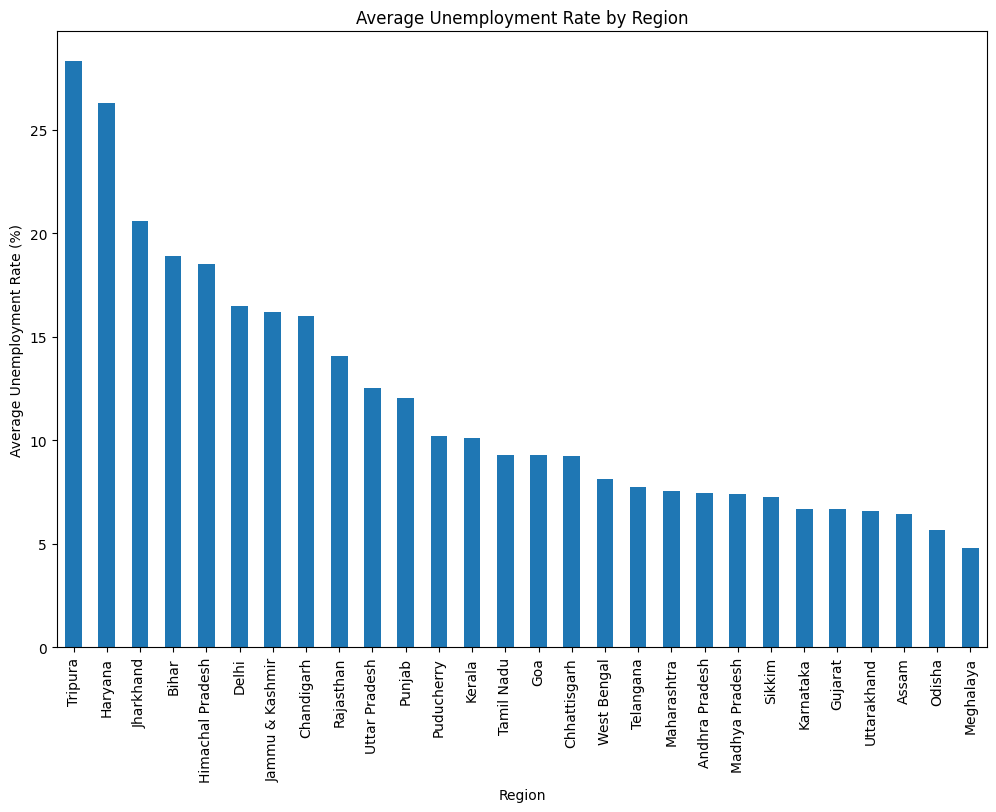

In [43]:
plt.figure(figsize=(12, 8))

region_avg.plot(kind='bar')

plt.title('Average Unemployment Rate by Region')
plt.xlabel('Region')
plt.ylabel('Average Unemployment Rate (%)')
plt.xticks(rotation=90)

plt.show()

### Observation

The bar chart shows that unemployment rates vary considerably across different regions of India. Some regions have noticeably higher average unemployment rates than others. This indicates that unemployment was not distributed equally across all regions during the period covered by the dataset.

In [44]:
monthly_unemployment = df.groupby('Date')['Estimated Unemployment Rate (%)'].mean()

monthly_unemployment

,Estimated Unemployment Rate (%)
Date,
2019-05-31,8.874259
2019-06-30,9.303333
2019-07-31,9.033889
2019-08-31,9.637925
2019-09-30,9.051731
2019-10-31,9.900909
2019-11-30,9.868364
2019-12-31,9.497358
2020-01-31,9.950755


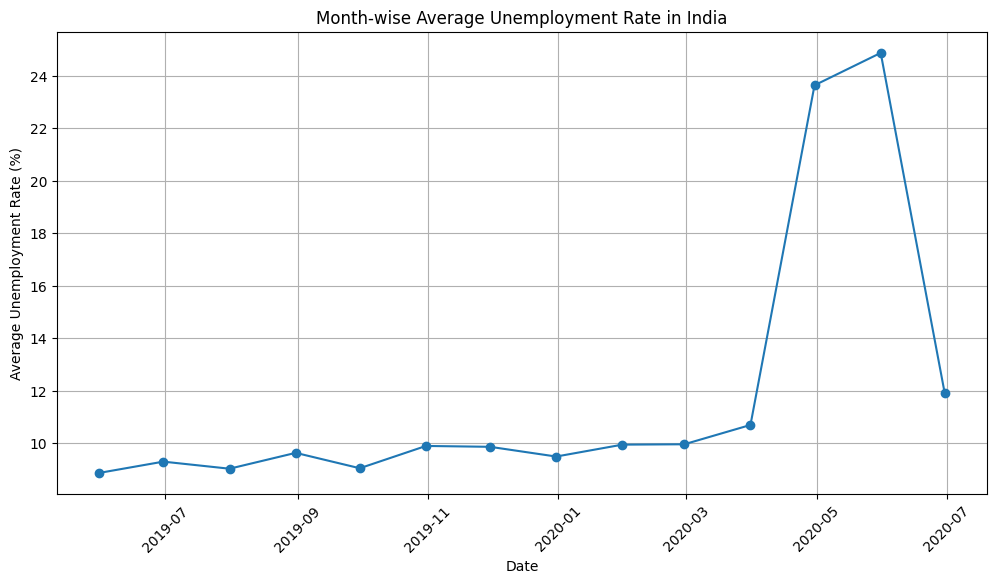

In [45]:
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_unemployment.index,
    monthly_unemployment.values,
    marker='o'
)

plt.title('Month-wise Average Unemployment Rate in India')
plt.xlabel('Date')
plt.ylabel('Average Unemployment Rate (%)')
plt.xticks(rotation=45)

plt.grid(True)
plt.show()

### Observation

The line chart shows how the average unemployment rate changed over time. The trend indicates that unemployment fluctuated during the period rather than remaining constant. A noticeable increase during the COVID-19 period can be investigated further using the pre-COVID and post-COVID comparison.

In [46]:
df['Region'].unique()

array(['Andhra Pradesh', 'Assam', 'Bihar', 'Chhattisgarh', 'Delhi', 'Goa',
       'Gujarat', 'Haryana', 'Himachal Pradesh', 'Jammu & Kashmir',
       'Jharkhand', 'Karnataka', 'Kerala', 'Madhya Pradesh',
       'Maharashtra', 'Meghalaya', 'Odisha', 'Puducherry', 'Punjab',
       'Rajasthan', 'Sikkim', 'Tamil Nadu', 'Telangana', 'Tripura',
       'Uttar Pradesh', 'Uttarakhand', 'West Bengal', nan, 'Chandigarh'],
      dtype=object)

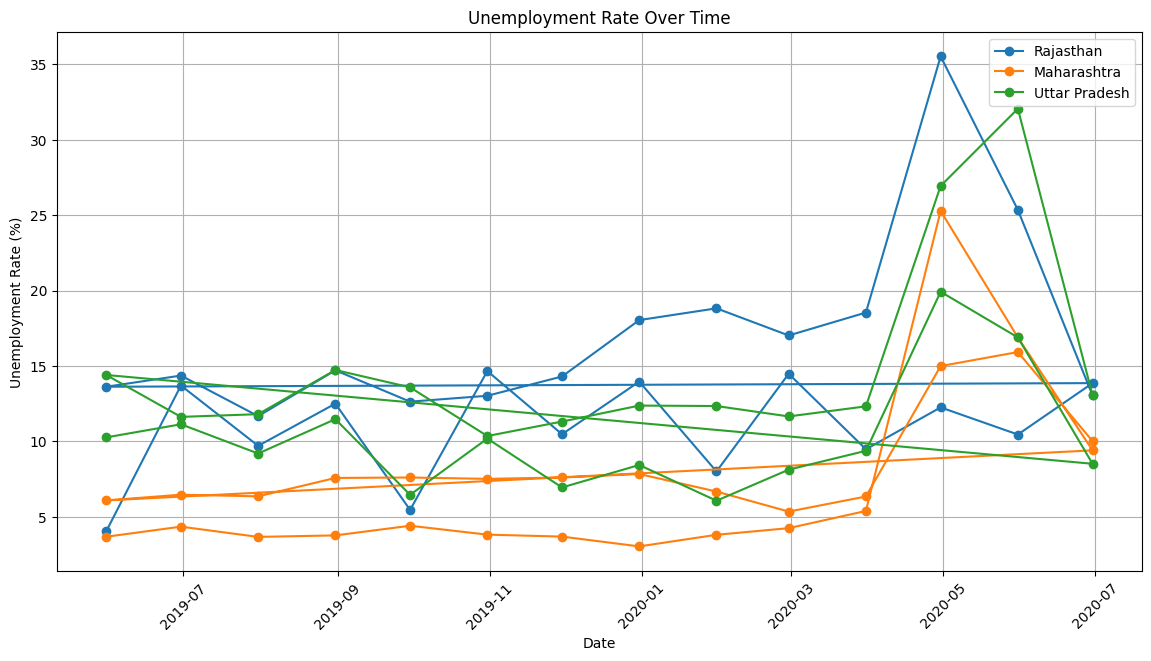

In [47]:
states = ['Rajasthan', 'Maharashtra', 'Uttar Pradesh']

plt.figure(figsize=(14, 7))

for state in states:
    state_data = df[df['Region'] == state]

    plt.plot(
        state_data['Date'],
        state_data['Estimated Unemployment Rate (%)'],
        marker='o',
        label=state
    )

plt.title('Unemployment Rate Over Time')
plt.xlabel('Date')
plt.ylabel('Unemployment Rate (%)')
plt.legend()
plt.grid(True)

plt.xticks(rotation=45)

plt.show()

In [48]:
top10 = region_avg.head(10)

top10

,Estimated Unemployment Rate (%)
Region,
Tripura,28.350357
Haryana,26.283214
Jharkhand,20.585000
Bihar,18.918214
Himachal Pradesh,18.540357
Delhi,16.495357
Jammu & Kashmir,16.188571
Chandigarh,15.991667
Rajasthan,14.058214


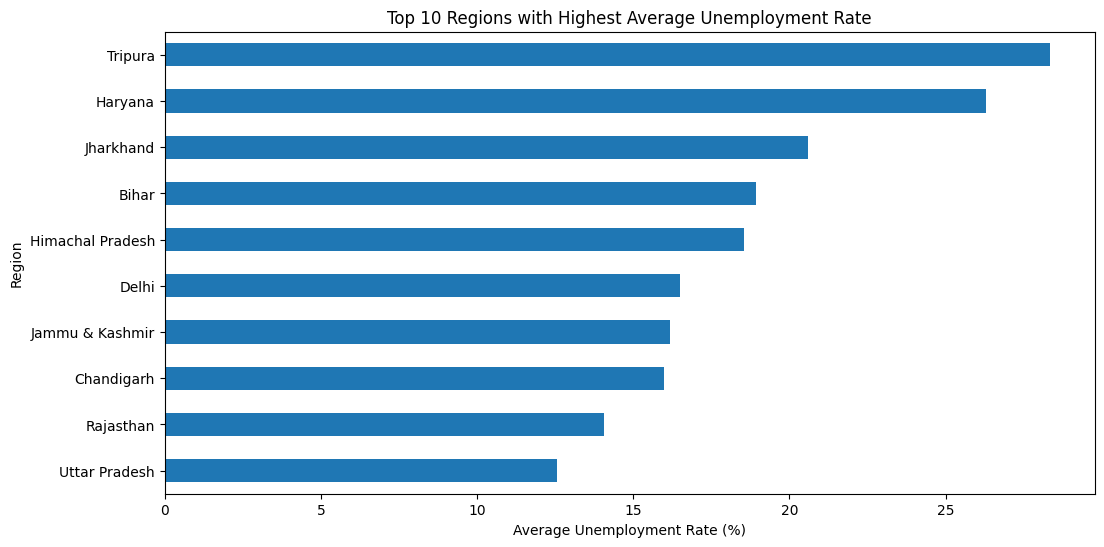

In [49]:
plt.figure(figsize=(12, 6))

top10.sort_values().plot(kind='barh')

plt.title('Top 10 Regions with Highest Average Unemployment Rate')
plt.xlabel('Average Unemployment Rate (%)')
plt.ylabel('Region')

plt.show()

### Observation

The chart presents the 10 regions with the highest average unemployment rates in the dataset. The values show that some regions experienced considerably higher unemployment than others. These differences may be related to regional economic conditions and should be interpreted within the time period represented by the dataset.

In [50]:
numeric_columns = [
    'Estimated Unemployment Rate (%)',
    'Estimated Employed',
    'Estimated Labour Participation Rate (%)'
]

correlation = df[numeric_columns].corr()

correlation

,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%)
Estimated Unemployment Rate (%),1.000000,-0.222876,0.002558
Estimated Employed,-0.222876,1.000000,0.011300
Estimated Labour Participation Rate (%),0.002558,0.011300,1.000000


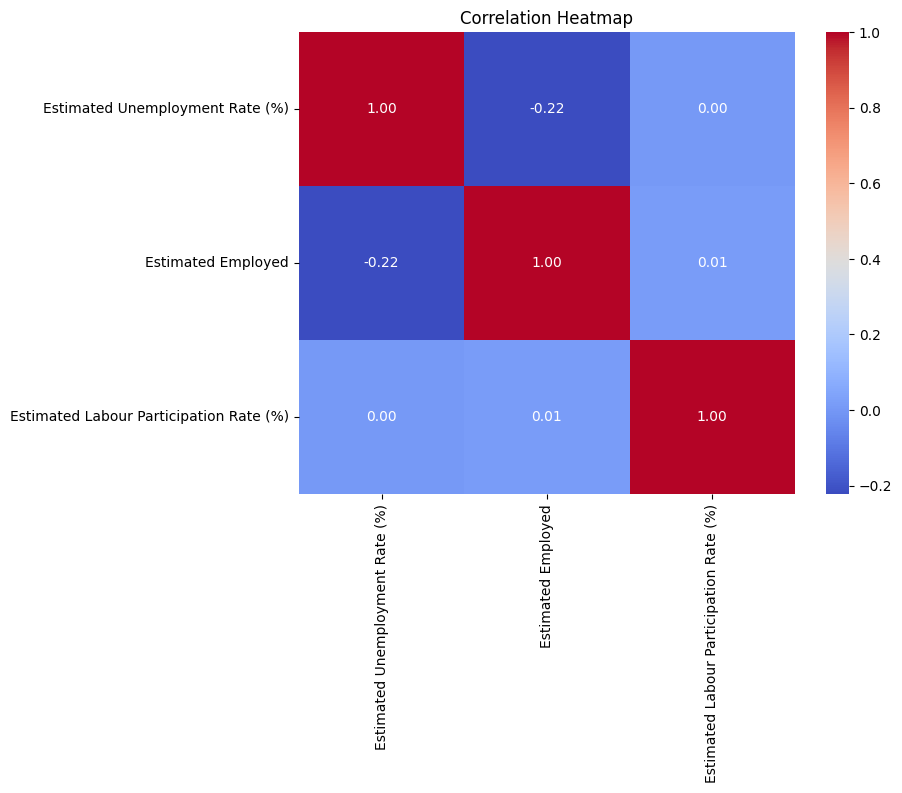

In [51]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')

plt.show()

### Observation

The correlation heatmap shows the relationship between unemployment rate, estimated employment and labour participation rate. Positive values indicate that two variables tend to increase together, while negative values indicate an inverse relationship. Correlation does not by itself prove that one variable causes another.

In [52]:
pre_covid = df[df['Date'] < '2020-03-01']

post_covid = df[df['Date'] >= '2020-03-01']

print("Pre-COVID records:", len(pre_covid))
print("COVID/Post-COVID records:", len(post_covid))

Pre-COVID records: 536
COVID/Post-COVID records: 204


In [53]:
pre_covid_avg = pre_covid['Estimated Unemployment Rate (%)'].mean()

post_covid_avg = post_covid['Estimated Unemployment Rate (%)'].mean()

print("Pre-COVID average unemployment:",
      round(pre_covid_avg, 2), "%")

print("COVID/Post-COVID average unemployment:",
      round(post_covid_avg, 2), "%")

Pre-COVID average unemployment: 9.51 %
COVID/Post-COVID average unemployment: 17.77 %


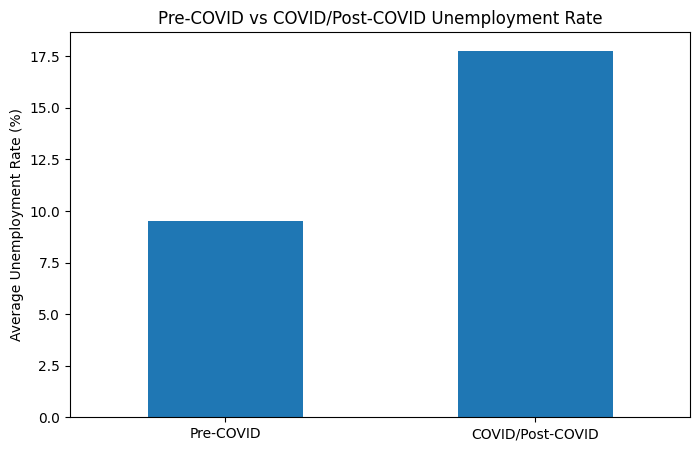

In [54]:
comparison = pd.Series({
    'Pre-COVID': pre_covid_avg,
    'COVID/Post-COVID': post_covid_avg
})

comparison.plot(kind='bar', figsize=(8, 5))

plt.title('Pre-COVID vs COVID/Post-COVID Unemployment Rate')
plt.ylabel('Average Unemployment Rate (%)')
plt.xticks(rotation=0)

plt.show()

### COVID-19 Observation

The comparison shows the difference between average unemployment before March 2020 and during the COVID/post-COVID period covered by the dataset. The change indicates how strongly unemployment conditions differed between these periods. The result should be interpreted as an association within this dataset and time period rather than as a complete measure of the pandemic's overall economic impact.

# Conclusion

This analysis explored unemployment patterns across different regions of India and over time. The analysis included regional averages, monthly trends, comparison of major states, the regions with the highest average unemployment rates, and correlations between unemployment, employment and labour participation.

The pre-COVID and COVID/post-COVID comparison provides an additional view of how unemployment conditions changed around the beginning of the pandemic period. Overall, the analysis demonstrates how Python, Pandas, Matplotlib and Seaborn can be used to explore and visualize unemployment data.